# Chapitre 5 - Cours 7 : workflows et exécution durable

Un mode de flux de données apparu dans la 2e édition du livre : les **moteurs de
workflows**. Dans une architecture de services, un traitement métier (un paiement)
enchaîne plusieurs appels à des services différents. Que se passe-t-il si le processus
qui orchestre ces appels tombe au milieu ? L'**exécution durable** répond en journalisant
chaque appel pour pouvoir **rejouer** le traitement sans refaire ce qui a déjà réussi. Ce
cours construit un mini-moteur d'exécution durable (`ddia/durable.py`, une centaine de
lignes) pour en voir le principe, la fenêtre dangereuse et les contraintes. Il couvre la
section *Durable Execution and Workflows*.

**Plan.**

1. Workflows, tâches et moteurs.
2. Le problème : une panne au milieu d'un paiement.
3. Journaliser et rejouer.
4. La fenêtre dangereuse et les clés d'idempotence.
5. Le prix du rejeu : déterminisme et code qui change.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia.durable import (Crash, Engine, ExternalService, NonDeterminismError, crash_once, crash_randomly)
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 70)

## 1. Workflows, tâches et moteurs (section *Durable Execution and Workflows*)

Prenons l'exemple du livre : une application de paiement débite une carte bancaire et
dépose les fonds sur un compte. Plusieurs services s'en partagent les étapes : détection
de fraude, intégration avec les cartes, intégration bancaire. Traiter **un** paiement
demande donc plusieurs appels : vérifier la fraude, débiter la carte, déposer à la
banque. Cette suite d'étapes s'appelle un **workflow**, et chaque étape une **tâche**
(Temporal parle d'« activité », d'autres de « fonction durable »). On décrit un workflow
comme un graphe de tâches, dans un langage de programmation, un langage dédié ou une
notation comme BPMN.

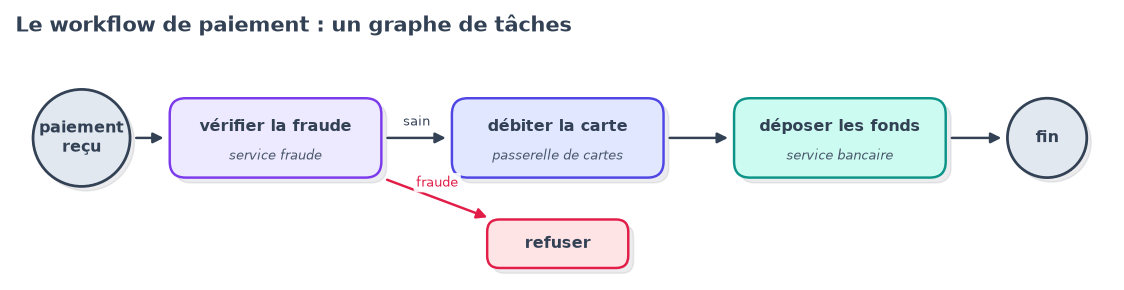

In [2]:
d = Diagram(12.5, 2.5, title="Le workflow de paiement : un graphe de tâches")
d.box("debut", 0.8, 1.6, "paiement\nreçu", color=SLATE, kind="circle", w=1.1)
d.box("fraude", 3.0, 1.6, "vérifier la fraude", sub="service fraude", color=VIOLET, w=2.4)
d.box("carte", 6.2, 1.6, "débiter la carte", sub="passerelle de cartes", color=INDIGO, w=2.4)
d.box("banque", 9.4, 1.6, "déposer les fonds", sub="service bancaire", color=TEAL, w=2.4)
d.box("fin", 11.75, 1.6, "fin", color=SLATE, kind="circle", w=0.9)
d.box("refus", 6.2, 0.4, "refuser", color=ROSE, w=1.6, h=0.55)
d.arrow("debut", "fraude"); d.arrow("fraude", "carte", "sain"); d.arrow("carte", "banque"); d.arrow("banque", "fin")
d.arrow("fraude", "refus", "fraude", color=ROSE)
d.show()

Un **moteur de workflows** exécute ces graphes : il décide quand et sur quelle machine
lancer chaque tâche, quoi faire si elle échoue (la machine plante), combien de tâches
peuvent tourner en parallèle. Il se compose en général d'un **orchestrateur**, qui
planifie les tâches, et d'**exécuteurs**, qui les exécutent. Un workflow est déclenché
par un calendrier (toutes les heures), par un service web, voire par un humain. Il en
existe pour bien des usages : orchestrer des traitements ETL (Airflow, Dagster, Prefect),
faire décrire les processus par des non-informaticiens en notation graphique (Camunda,
Orkes), ou offrir l'**exécution durable** (Temporal, Restate).

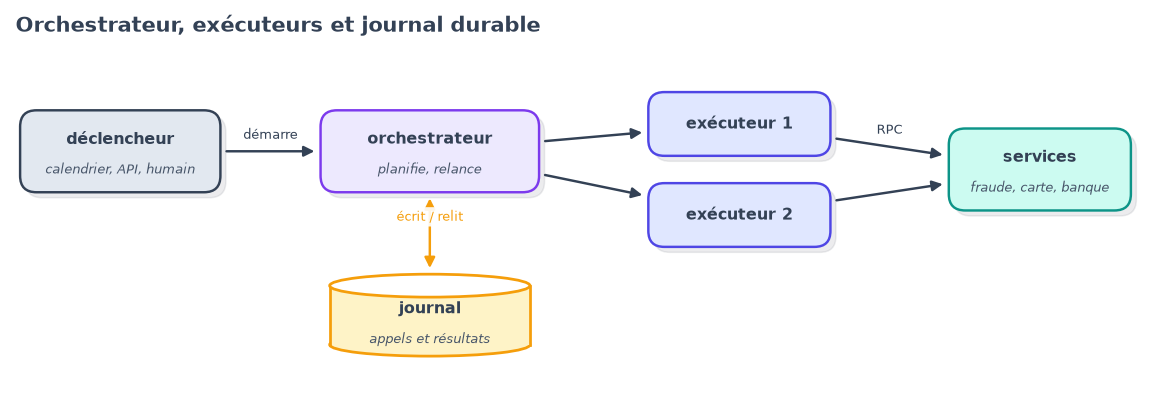

In [3]:
d = Diagram(12.5, 3.6, title="Orchestrateur, exécuteurs et journal durable")
d.box("trig", 1.2, 2.6, "déclencheur", sub="calendrier, API, humain", color=SLATE, w=2.2)
d.box("orch", 4.6, 2.6, "orchestrateur", sub="planifie, relance", color=VIOLET, w=2.4)
d.box("log", 4.6, 0.8, "journal", sub="appels et résultats", color=AMBER, kind="db", w=2.2, h=0.9)
d.box("ex1", 8.0, 2.9, "exécuteur 1", color=INDIGO, w=2.0, h=0.7)
d.box("ex2", 8.0, 1.9, "exécuteur 2", color=INDIGO, w=2.0, h=0.7)
d.box("svc", 11.3, 2.4, "services", sub="fraude, carte, banque", color=TEAL, w=2.0)
d.arrow("trig", "orch", "démarre")
d.arrow("orch", "log", "écrit / relit", both=True, color=AMBER)
d.arrow("orch", "ex1"); d.arrow("orch", "ex2")
d.arrow("ex1", "svc", "RPC"); d.arrow("ex2", "svc")
d.show()

> **À retenir.** Un workflow est un graphe de tâches (souvent des appels de services) ; un
> moteur de workflows (orchestrateur et exécuteurs) les planifie, les exécute et gère les
> pannes.

## 2. Le problème : une panne au milieu d'un paiement

On voudrait traiter chaque paiement **exactement une fois**. Mais une panne pendant le
workflow peut laisser une carte débitée sans dépôt correspondant. Dans une architecture
de services, on ne peut pas envelopper les deux tâches dans une transaction de base de
données (et la passerelle de paiement appartient peut-être à un tiers). Écrivons le
workflow avec notre mini-moteur : chaque appel de service passe par `ctx.activity`.

In [4]:
def nouveaux_services(idempotents=False):
    return (ExternalService("carte", idempotent=idempotents), ExternalService("banque", idempotent=idempotents))

def workflow_paiement(carte, banque, avec_cle=True):
    def verifier_fraude(montant):
        return montant > 10_000

    def paiement(ctx, montant):
        if ctx.activity(verifier_fraude, montant):
            return "refusé"
        ctx.activity(carte, montant, name="débit carte", with_key=avec_cle)
        ctx.activity(banque, montant, name="dépôt banque", with_key=avec_cle)
        return "payé"
    return paiement

# Un script ordinaire, relancé depuis le début après une panne juste avant le dépôt
carte, banque = nouveaux_services()
script = Engine(crash=crash_once("before", "dépôt banque"), durable=False)
print("script ordinaire :", script.start("p-1", workflow_paiement(carte, banque), 120),
      f"| débits carte : {len(carte.effects)}, dépôts : {len(banque.effects)}, relances : {script.restarts}")

script ordinaire : payé | débits carte : 2, dépôts : 1, relances : 1


Relancé depuis le début, le script ordinaire **débite la carte deux fois** (une fois avant
la panne, une fois après la relance). Ne pas relancer serait pire : la carte resterait
débitée sans dépôt.

> **À retenir.** Un workflow qui enchaîne des appels à des services ne peut pas compter
> sur une transaction. Après une panne, ni « tout refaire » ni « abandonner » ne donnent
> un traitement exactement une fois.

## 3. Journaliser et rejouer

Les frameworks d'exécution durable apportent la sémantique « exactement une fois » aux
workflows. Leur idée : **journaliser** dans un stockage durable chaque appel RPC et chaque
changement d'état, un peu comme un journal d'écriture anticipée (write-ahead log) d'une
base. Si une tâche échoue, le framework la **réexécute**, mais **saute** les appels qui
avaient réussi : il fait semblant de les refaire et renvoie le résultat enregistré.

Notre moteur fait exactement cela : `ctx.activity` regarde si l'étape courante figure
déjà au journal ; si oui, elle renvoie le résultat enregistré (rejeu) ; sinon, elle
exécute l'appel, puis l'enregistre.

In [5]:
carte, banque = nouveaux_services()
moteur = Engine(crash=crash_once("before", "dépôt banque"))
print("exécution durable :", moteur.start("p-1", workflow_paiement(carte, banque), 120),
      f"| débits carte : {len(carte.effects)}, dépôts : {len(banque.effects)}, relances : {moteur.restarts}")
pd.DataFrame([vars(e) for e in moteur.store["p-1"]["history"]])

exécution durable : payé | débits carte : 1, dépôts : 1, relances : 1


,seq,kind,name,result
0,0,activity,verifier_fraude,False
1,1,activity,débit carte,carte-1
2,2,activity,dépôt banque,banque-1


Une seule panne, une relance, et cette fois **un** débit et **un** dépôt. Le journal
contient le résultat de chaque étape. Voici le déroulement, reconstitué à partir de la
trace du moteur : à la deuxième tentative, les deux premières étapes sont **rejouées**
(relues dans le journal, instantanément) et seule la dernière est réellement exécutée.

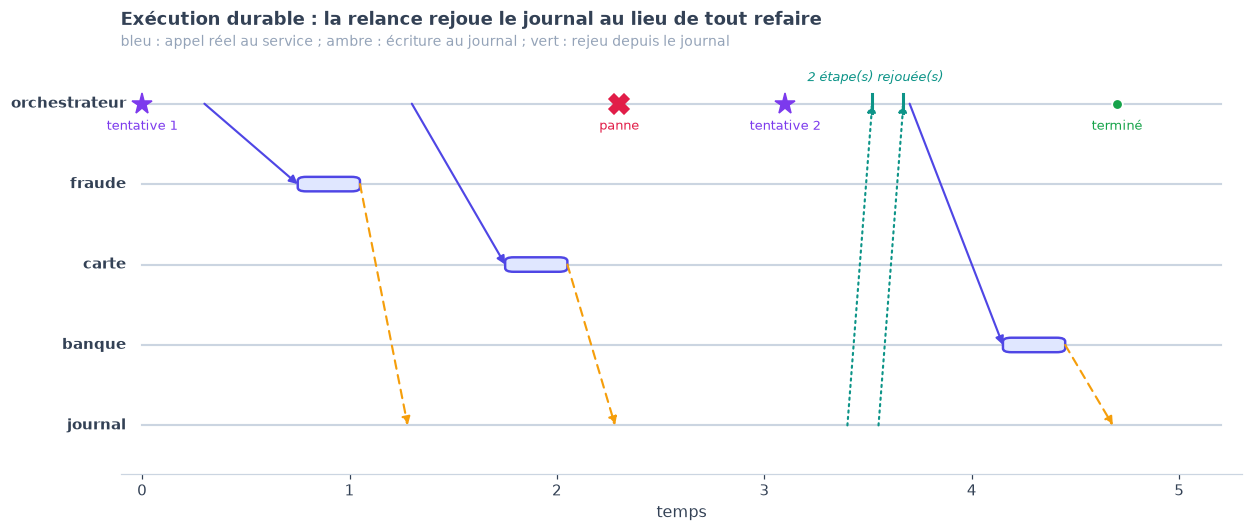

In [6]:
def trace_en_espace_temps(moteur, titre, sous_titre):
    t_max = moteur.t + 0.5
    st = SpaceTime(["orchestrateur", "fraude", "carte", "banque", "journal"], t_max=t_max, width=11.5,
                   title=titre, subtitle=sous_titre, lane_height=0.85)
    lane = {"verifier_fraude": "fraude", "débit carte": "carte", "dépôt banque": "banque"}
    for L in moteur.log:
        if L.action == "start":
            st.event("orchestrateur", L.t, f"tentative {L.attempt}", kind="star", color=VIOLET)
        elif L.action == "exec":
            st.msg("orchestrateur", L.t, lane[L.name], L.t + 0.45, "", color=INDIGO)
            st.op(lane[L.name], L.t + 0.45, L.t + 0.75, "", color=INDIGO)
            st.msg(lane[L.name], L.t + 0.75, "journal", L.t + 0.98, "", color=AMBER, style="dashed")
        elif L.action == "replay":
            st.msg("journal", L.t, "orchestrateur", L.t + 0.12, "", color=TEAL, style="dotted")
            st.event("orchestrateur", L.t + 0.12, kind="tick", color=TEAL)
        elif L.action == "crash":
            st.event("orchestrateur", L.t, "panne", kind="crash")
        elif L.action == "done":
            st.event("orchestrateur", L.t, "terminé", kind="point", color=GREEN)
    rejeux = [L for L in moteur.log if L.action == "replay"]
    for k in sorted({L.attempt for L in rejeux}):
        r = [L.t for L in rejeux if L.attempt == k]
        st.note(np.mean(r) + 0.06, "orchestrateur", f"{len(r)} étape(s) rejouée(s)", dy=0.33, color=TEAL)
    st.show()

trace_en_espace_temps(moteur, "Exécution durable : la relance rejoue le journal au lieu de tout refaire",
                      "bleu : appel réel au service ; ambre : écriture au journal ; vert : rejeu depuis le journal")

> **À retenir.** L'exécution durable journalise le résultat de chaque appel ; après une
> panne, elle réexécute le workflow depuis le début en **rejouant** les appels déjà faits
> (résultats lus dans le journal) et n'exécute réellement que les suivants.

## 4. La fenêtre dangereuse et les clés d'idempotence

Le journal n'efface pas toute difficulté. Entre le moment où le service externe a
**effectué** l'action et celui où le moteur **enregistre** le résultat, une panne laisse
l'appel non journalisé : au rejeu, le moteur le refait. Le livre insiste : les services
externes (la passerelle de paiement) doivent toujours offrir une API **idempotente**, et
le développeur doit leur passer des **identifiants uniques** pour empêcher l'exécution en
double. Notre moteur fournit une clé stable `identifiant-du-workflow/étape`, la même à
chaque réexécution (`with_key=True`).

In [7]:
rows = []
for nom, idem in [("service non idempotent", False), ("service idempotent + clé stable", True)]:
    carte, banque = nouveaux_services(idempotents=idem)
    m = Engine(crash=crash_once("after", "débit carte"))
    m.start("p-2", workflow_paiement(carte, banque), 120)
    rows.append({"cas": nom, "appels reçus par la carte": carte.calls, "débits réels": len(carte.effects),
                 "dépôts": len(banque.effects)})
pd.DataFrame(rows).set_index("cas")

,appels reçus par la carte,débits réels,dépôts
cas,,,
service non idempotent,2,2,1
service idempotent + clé stable,2,1,1


La panne survient juste après le débit, avant la journalisation : le moteur rappelle la
carte. Sans idempotence, deux débits ; avec une clé stable, la passerelle reconnaît la
requête et renvoie la réponse précédente (deux appels, un seul débit).

Mesurons sur 2 000 paiements avec des pannes aléatoires à chaque frontière d'étape, pour
trois stratégies : script relancé depuis le début, exécution durable sans idempotence,
exécution durable avec clés et services idempotents.

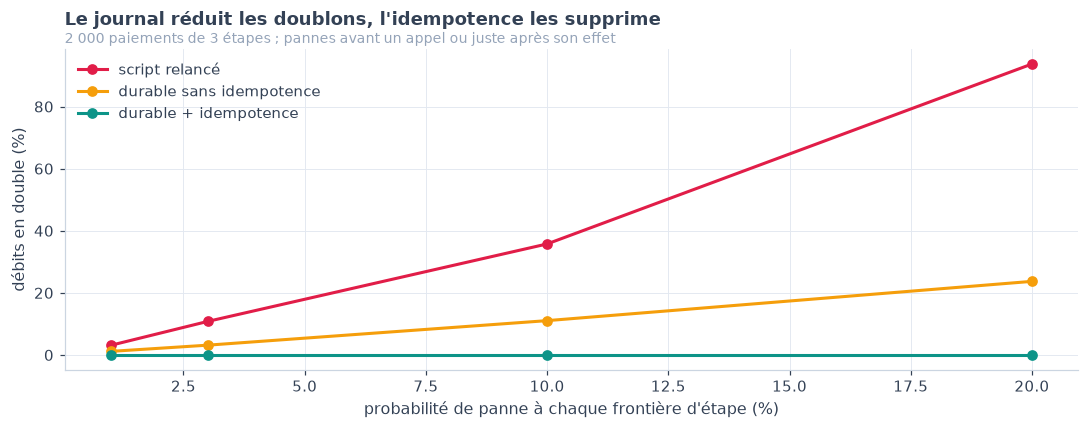

stratégie,durable + idempotence,durable sans idempotence,script relancé
p,,,
0.01,0.0,1.25,3.20
0.03,0.0,3.25,10.90
0.10,0.0,11.15,35.85
0.20,0.0,23.80,93.80


In [8]:
def campagne(p, strategie, n=2000, seed=0):
    idem = strategie == "durable + idempotence"
    carte, banque = nouveaux_services(idempotents=idem)
    m = Engine(crash=crash_randomly(p, seed=seed), durable=strategie != "script relancé", max_restarts=10 ** 6)
    for k in range(n):
        m.start(f"p-{k}", workflow_paiement(carte, banque, avec_cle=idem), 100)
    return {"débits en double (%)": (len(carte.effects) - n) / n * 100,
            "relances par paiement": m.restarts / n,
            "écritures au journal par paiement": m.journal_writes / n}

ps = [0.01, 0.03, 0.1, 0.2]
strategies = ["script relancé", "durable sans idempotence", "durable + idempotence"]
res = pd.DataFrame([{"p": p, "stratégie": s, **campagne(p, s)} for p in ps for s in strategies])
fig, ax = plt.subplots(figsize=(10, 4))
for s, c in zip(strategies, [ROSE, AMBER, TEAL]):
    r = res[res["stratégie"] == s]
    ax.plot(r.p * 100, r["débits en double (%)"], "o-", color=c, label=s)
ax.set_xlabel("probabilité de panne à chaque frontière d'étape (%)"); ax.set_ylabel("débits en double (%)")
ax.set_title("Le journal réduit les doublons, l'idempotence les supprime")
subtitle(ax, "2 000 paiements de 3 étapes ; pannes avant un appel ou juste après son effet")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
res.pivot(index="p", columns="stratégie", values="débits en double (%)").round(2)

Le script relancé depuis le début refait le débit après toute panne survenue plus loin
dans le workflow ; l'exécution durable ne le refait qu'après une panne dans la petite
fenêtre entre l'effet et la journalisation (deux à quatre fois moins de doublons ici, et
l'écart grandirait avec des workflows plus longs) ; avec des clés d'idempotence, **zéro**
doublon quel que soit le taux de pannes. La sémantique « exactement une fois » des
frameworks d'exécution durable repose donc, au bout de la chaîne, sur l'idempotence des
services appelés.

> **À retenir.** Une panne entre l'effet d'un appel et sa journalisation provoque une
> réexécution. Les services externes doivent être idempotents et recevoir une clé unique
> et stable par étape : le journal plus l'idempotence donnent l'effet « exactement une
> fois ».